In [1]:
"""
from google.colab import drive
from pathlib import Path
drive.mount("/content/drive")
"""

'\nfrom google.colab import drive\nfrom pathlib import Path\ndrive.mount("/content/drive")\n'

If you haven't already:

1. Open the shared folder link in Google Drive:  
   https://drive.google.com/drive/folders/1fm2lM_DcFoASB4RRQIesk9e5mJlLoIl9?usp=sharing
2. Right-click the folder **`celeba`** → **Add shortcut to Drive**
3. Put the shortcut somewhere inside **My Drive**
4. **Copy the path** to the folder that contains `celeba`

Then, in the notebook, **set the root path manually** so that it points to the **parent directory of `celeba`**:

```python
# Example (change this to YOUR actual path in My Drive)
CELEBA_ROOT = Path("/content/drive/MyDrive/datasets")

# This must exist:
# /content/drive/MyDrive/datasets/celeba/

In [2]:
CELEBA_ROOT = "/Volumes/extreme ssd"

In [3]:
from torchvision.datasets import CelebA
from torchvision import transforms

transform = transforms.Compose([
    transforms.CenterCrop(178),
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
])

dataset = CelebA(
    root=str(CELEBA_ROOT),
    split="train",
    target_type="attr",
    transform=transform,
    download=False  # <--- we already have the files in Drive
)

val_dataset = CelebA(root=str(CELEBA_ROOT), split="valid", target_type="attr", transform=transform, download=False)
test_dataset = CelebA(root=str(CELEBA_ROOT), split="test",  target_type="attr", transform=transform, download=False)

print("Train size:", len(dataset))
print("Valid size:", len(val_dataset))
print("Test size:", len(test_dataset))


Train size: 162770
Valid size: 19867
Test size: 19962


In [4]:
img, attrs = dataset[0]
print("Image tensor shape:", img.shape)  # [3, 128, 128]
print("Attrs shape:", attrs.shape)       # [40]
print("Attrs (first 10):", attrs[:10])

Image tensor shape: torch.Size([3, 64, 64])
Attrs shape: torch.Size([40])
Attrs (first 10): tensor([0, 1, 1, 0, 0, 0, 0, 0, 0, 0])


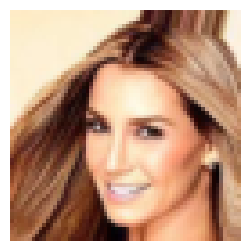

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(3,3))
plt.imshow(img.permute(1,2,0))
plt.axis("off")
plt.show()


### MY WORK STARTS HERE

- Use ResNet-18, available through torchvision.models

- Initialize the model with ImageNet-pretrained weights

- Remove the final classification layer

- Use the same shared backbone for all model variants you evaluate

# Part 1 
---
## 1) Baseline classifier (x → y)
A standard image classifier that directly maps images to labels.

- Backbone: convolutional neural network

    - Lightweight version: a small CNN of your design

    - Heavy version: ResNet-18 (We're using this version for the project!) 

- Single classification head

#### Report:

- Test accuracy

- Test AUROC

In [6]:
import copy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from torchvision.models import resnet18, ResNet18_Weights

TARGET_NAME = "Smiling"

CONCEPT_NAMES = [
    "Mouth_Slightly_Open",
    "High_Cheekbones",
    "Chubby",
    "Narrow_Eyes",
    "Bags_Under_Eyes",
    "Big_Lips",
    "Big_Nose",
    "Pointy_Nose",
    "Bushy_Eyebrows",
    "Arched_Eyebrows",
]

# Load ResNet-18 with a specific set of ImageNet-pretrained weights.
weights = ResNet18_Weights.IMAGENET1K_V1
resnet = resnet18(weights=weights)

# Record the number of features entering the original classifier.
feature_dim = resnet.fc.in_features  # 512

# Replace the original classifier with a pass-through operation.
resnet.fc = nn.Identity()

# The pretrained weights expect ImageNet-normalised inputs (the same statistics that
# weights.transforms() uses). Images stay in [0, 1] outside the model, which keeps
# caching, augmentation and plotting simple.
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)


class ImageNetNormalize(nn.Module):
    """Normalises [0, 1] images inside the model, so every variant shares it."""

    def __init__(self, mean, std):
        super().__init__()
        self.register_buffer("mean", torch.tensor(mean).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(std).view(1, 3, 1, 1))

    def forward(self, images):
        return (images - self.mean) / self.std


# Shared backbone template: normalisation + ResNet-18 without its classifier.
# Every model below starts from its own deep copy of this untouched template.
backbone = nn.Sequential(ImageNetNormalize(IMAGENET_MEAN, IMAGENET_STD), resnet)

print("Features per image:", feature_dim)

Features per image: 512


In [7]:
class BaselineClassifier(nn.Module):
    def __init__(self, backbone, feature_dim):
        super().__init__()
        self.backbone = backbone
        self.head = nn.Linear(feature_dim, 1)

    def forward(self, images):
        features = self.backbone(images)        # Shape: (batch_size, 512)
        logits = self.head(features)            # Shape: (batch_size, 1)
        return logits.squeeze(-1)               # Shape: (batch_size,)


# Select an available device.
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Training device:", device)
# The model and optimizer are now created in the training cell, so re-running that
# cell always starts from the pretrained weights instead of continuing training.

Training device: mps


In [8]:
from sklearn.metrics import accuracy_score, roc_auc_score


def binary_scores(y_true, logits):
    """Accuracy at P = 0.5 (logit 0) and threshold-free AUROC."""
    y_true = np.asarray(y_true).reshape(-1).astype(int)
    logits = np.asarray(logits, dtype=float).reshape(-1)
    return {
        "accuracy": float(accuracy_score(y_true, (logits >= 0).astype(int))),
        "auroc": float(roc_auc_score(y_true, logits)),
    }


@torch.no_grad()
def predict_logits(model, loader, target_index=None, run_device=None):
    """(labels, logits) on the CPU for a model that maps images to one logit."""
    target_index = smiling_index if target_index is None else target_index
    run_device = device if run_device is None else run_device
    model.eval()
    all_labels, all_logits = [], []
    for images, attributes in loader:
        all_logits.append(model(images.to(run_device)).float().cpu())
        all_labels.append(attributes[:, target_index].cpu())
    return torch.cat(all_labels), torch.cat(all_logits)


def evaluate(model, loader, smiling_index, device):
    """Same interface and outputs as the original evaluate()."""
    y_true, logits = predict_logits(model, loader, smiling_index, device)
    return binary_scores(y_true, logits)


def bootstrap_ci(y_true, logits, n_boot=1000, seed=0):
    """95% percentile-bootstrap intervals for accuracy and AUROC (resampling test images)."""
    y_true = np.asarray(y_true).reshape(-1).astype(int)
    logits = np.asarray(logits, dtype=float).reshape(-1)
    rng = np.random.default_rng(seed)
    accuracies, aurocs = [], []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        if y_true[idx].min() == y_true[idx].max():
            continue
        accuracies.append(((logits[idx] >= 0) == y_true[idx]).mean())
        aurocs.append(roc_auc_score(y_true[idx], logits[idx]))
    return np.percentile(accuracies, [2.5, 97.5]), np.percentile(aurocs, [2.5, 97.5])


def paired_difference_ci(y_true, logits_a, logits_b, n_boot=1000, seed=0):
    """Point estimate and 95% bootstrap CI of (model A − model B) on the SAME test images."""
    y_true = np.asarray(y_true).reshape(-1).astype(int)
    a = np.asarray(logits_a, dtype=float).reshape(-1)
    b = np.asarray(logits_b, dtype=float).reshape(-1)
    rng = np.random.default_rng(seed)
    accuracy_differences, auroc_differences = [], []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        yb = y_true[idx]
        if yb.min() == yb.max():
            continue
        accuracy_differences.append(((a[idx] >= 0) == yb).mean() - ((b[idx] >= 0) == yb).mean())
        auroc_differences.append(roc_auc_score(yb, a[idx]) - roc_auc_score(yb, b[idx]))
    scores_a, scores_b = binary_scores(y_true, a), binary_scores(y_true, b)
    return {
        "accuracy_difference": scores_a["accuracy"] - scores_b["accuracy"],
        "accuracy_ci": np.percentile(accuracy_differences, [2.5, 97.5]),
        "auroc_difference": scores_a["auroc"] - scores_b["auroc"],
        "auroc_ci": np.percentile(auroc_differences, [2.5, 97.5]),
    }


def score_row(name, y_true, logits):
    """One summary-table row with bootstrap 95% CIs."""
    scores = binary_scores(y_true, logits)
    accuracy_ci, auroc_ci = bootstrap_ci(y_true, logits)
    return {
        "Model": name,
        "Test accuracy": scores["accuracy"],
        "Accuracy 95% CI": f"[{accuracy_ci[0]:.3f}, {accuracy_ci[1]:.3f}]",
        "Test AUROC": scores["auroc"],
        "AUROC 95% CI": f"[{auroc_ci[0]:.3f}, {auroc_ci[1]:.3f}]",
    }

---
### The following cell partitions the datasets to work locally or use the full dataset when possible.

Full dataset variables:

    - dataset
    
    - val_dataset
    
    - tes_dataset
    

Subset Variables: 

    - train_subset
    
    - valid_subset
    
    - test_subset 

To use the full dataset, change the dataset variables in the data loaders.  
    
---

In [9]:
from torch.utils.data import Subset

# 10,000 images in total; change these three sizes if needed.
N_TRAIN = 5_000
N_VALID = 1_000
N_TEST = 1_000

# Fix the selection so every model can use the same images.
subset_generator = torch.Generator().manual_seed(42)

def take_subset(full_dataset, size):
    assert 1 <= size <= len(full_dataset)
    indices = torch.randperm(
        len(full_dataset), generator=subset_generator
    )[:size].tolist()
    return Subset(full_dataset, indices)

train_subset = take_subset(dataset, N_TRAIN)
valid_subset = take_subset(val_dataset, N_VALID)
test_subset = take_subset(test_dataset, N_TEST)

print("Selected train / valid / test:",
      len(train_subset), len(valid_subset), len(test_subset))



Selected train / valid / test: 5000 1000 1000


---

In [10]:
from torch.utils.data import DataLoader, Dataset

BATCH_SIZE = 32
USE_HFLIP_AUGMENTATION = True  # random left-right flips, training images only
SAVE_CACHE_TO_DISK = True      # avoids re-reading the JPEGs after a kernel restart
CACHE_FILE = Path(f"celeba64_subset_cache_{N_TRAIN}_{N_VALID}_{N_TEST}_seed42.pt")


@torch.no_grad()
def cache_split(subset, split_name, batch_size=256):
    """Decodes a subset once and stores it as uint8 (exact: ToTensor() = uint8 / 255)."""
    loader = DataLoader(subset, batch_size=batch_size, shuffle=False, num_workers=0)
    images, attributes = [], []
    for batch_number, (batch_images, batch_attributes) in enumerate(loader, start=1):
        images.append(batch_images.mul(255).round().to(torch.uint8))
        attributes.append(batch_attributes)
        if batch_number == 1 or batch_number % 10 == 0 or batch_number == len(loader):
            print(f"Caching {split_name} | batch {batch_number}/{len(loader)}", flush=True)
    return torch.cat(images), torch.cat(attributes)


subset_indices = {
    "train": torch.tensor(train_subset.indices),
    "valid": torch.tensor(valid_subset.indices),
    "test": torch.tensor(test_subset.indices),
}

cache = None
if SAVE_CACHE_TO_DISK and CACHE_FILE.exists():
    cache = torch.load(CACHE_FILE)
    if all(torch.equal(cache[f"{split}_indices"], indices)
           for split, indices in subset_indices.items()):
        print("Loaded cached images from", CACHE_FILE)
    else:
        print("Cache does not match the current subsets; rebuilding it.")
        cache = None

if cache is None:
    cache = {}
    for split, subset in [("train", train_subset), ("valid", valid_subset), ("test", test_subset)]:
        cache[f"{split}_images"], cache[f"{split}_attributes"] = cache_split(subset, split)
        cache[f"{split}_indices"] = subset_indices[split]
    if SAVE_CACHE_TO_DISK:
        torch.save(cache, CACHE_FILE)
        print("Saved cache to", CACHE_FILE)


class CachedImages(Dataset):
    """Cached uint8 images served as float tensors in [0, 1], with optional random flips."""

    def __init__(self, images, attributes, hflip=False):
        self.images = images
        self.attributes = attributes
        self.hflip = hflip

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        image = self.images[index].float().div(255)
        if self.hflip and torch.rand(()) < 0.5:
            image = image.flip(-1)
        return image, self.attributes[index]


train_loader = DataLoader(
    CachedImages(cache["train_images"], cache["train_attributes"], hflip=USE_HFLIP_AUGMENTATION),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(42),
)
# Same training images, unshuffled and unaugmented: used to extract frozen outputs (Parts 3-4).
train_eval_loader = DataLoader(
    CachedImages(cache["train_images"], cache["train_attributes"]),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
)
valid_loader = DataLoader(
    CachedImages(cache["valid_images"], cache["valid_attributes"]),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
)
test_loader = DataLoader(
    CachedImages(cache["test_images"], cache["test_attributes"]),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
)

# Locate the target and concepts by name.
smiling_index = dataset.attr_names.index(TARGET_NAME)
concept_indices = [dataset.attr_names.index(name) for name in CONCEPT_NAMES]
num_concepts = len(CONCEPT_NAMES)
train_attributes = cache["train_attributes"]

print("Cached train / valid / test:",
      len(train_loader.dataset), len(valid_loader.dataset), len(test_loader.dataset))
print(f"Smiling prevalence — train: {train_attributes[:, smiling_index].float().mean():.3f}, "
      f"test: {cache['test_attributes'][:, smiling_index].float().mean():.3f}")

Loaded cached images from celeba64_subset_cache_5000_1000_1000_seed42.pt
Cached train / valid / test: 5000 1000 1000
Smiling prevalence — train: 0.477, test: 0.494


In [11]:
NUM_FINETUNE_EPOCHS = 8  # shared by every model that fine-tunes the backbone (Parts 1 and 2)
BASELINE_LEARNING_RATE = 1e-4

torch.manual_seed(42)
# Give this experiment its own copy, preserving the original backbone template.
baseline = BaselineClassifier(
    backbone=copy.deepcopy(backbone),
    feature_dim=feature_dim,
).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(baseline.parameters(), lr=BASELINE_LEARNING_RATE)

best_valid_auroc = float("-inf")
best_state = None
best_epoch = None
baseline_history = []

for epoch in range(NUM_FINETUNE_EPOCHS):
    baseline.train()
    total_loss = 0.0

    for images, attributes in train_loader:
        images = images.to(device)
        labels = attributes[:, smiling_index].float().to(device)

        optimizer.zero_grad(set_to_none=True)
        loss = criterion(baseline(images), labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

    train_loss = total_loss / len(train_loader.dataset)
    valid_metrics = evaluate(baseline, valid_loader, smiling_index, device)
    baseline_history.append({
        "Epoch": epoch + 1,
        "Train BCE": train_loss,
        "Validation accuracy": valid_metrics["accuracy"],
        "Validation AUROC": valid_metrics["auroc"],
    })

    if valid_metrics["auroc"] > best_valid_auroc:
        best_valid_auroc = valid_metrics["auroc"]
        best_state = {name: value.detach().cpu().clone()
                      for name, value in baseline.state_dict().items()}
        best_epoch = epoch + 1

    print(
        f"Epoch {epoch + 1}/{NUM_FINETUNE_EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Validation accuracy: {valid_metrics['accuracy']:.4f} | "
        f"Validation AUROC: {valid_metrics['auroc']:.4f}"
    )

# Restore the checkpoint selected using validation data.
baseline.load_state_dict(best_state)
if best_epoch == NUM_FINETUNE_EPOCHS:
    print("Note: the last epoch was best; NUM_FINETUNE_EPOCHS may be too small.")

# Keep the logits: every later model is compared with these, image by image.
baseline_valid_y, baseline_valid_logits = predict_logits(baseline, valid_loader)
baseline_test_y, baseline_test_logits = predict_logits(baseline, test_loader)
test_metrics = binary_scores(baseline_test_y, baseline_test_logits)
baseline_test_metrics = dict(test_metrics)
accuracy_ci, auroc_ci = bootstrap_ci(baseline_test_y, baseline_test_logits)

print(f"Selected epoch: {best_epoch}")
print(f"Test accuracy: {test_metrics['accuracy']:.2%}  (95% CI {accuracy_ci[0]:.1%} – {accuracy_ci[1]:.1%})")
print(f"Test AUROC: {test_metrics['auroc']:.4f}  (95% CI {auroc_ci[0]:.4f} – {auroc_ci[1]:.4f})")

Epoch 1/8 | Train loss: 0.5157 | Validation accuracy: 0.8360 | Validation AUROC: 0.9140
Epoch 2/8 | Train loss: 0.2474 | Validation accuracy: 0.8630 | Validation AUROC: 0.9420
Epoch 3/8 | Train loss: 0.1766 | Validation accuracy: 0.8590 | Validation AUROC: 0.9411
Epoch 4/8 | Train loss: 0.1266 | Validation accuracy: 0.8690 | Validation AUROC: 0.9526
Epoch 5/8 | Train loss: 0.0958 | Validation accuracy: 0.8600 | Validation AUROC: 0.9449
Epoch 6/8 | Train loss: 0.0688 | Validation accuracy: 0.8530 | Validation AUROC: 0.9491
Epoch 7/8 | Train loss: 0.0657 | Validation accuracy: 0.8690 | Validation AUROC: 0.9462
Epoch 8/8 | Train loss: 0.0422 | Validation accuracy: 0.8600 | Validation AUROC: 0.9433
Selected epoch: 4
Test accuracy: 89.10%  (95% CI 87.2% – 90.9%)
Test AUROC: 0.9590  (95% CI 0.9480 – 0.9687)


#### Part 1 — notes
- The training loss heads towards zero within a few epochs (0.04 in the original run) while validation AUROC plateaus: with 5,000 images the network memorises the training set, so choosing the checkpoint on validation AUROC is what protects the test result.
- Report the confidence interval, not just the point estimate. With 1,000 test images, accuracy is only known to roughly ±2 percentage points.
- This model is the reference for Parts 3–4. Its test logits are kept (`baseline_test_logits`) so later comparisons are *paired* on identical images, which is more sensitive than comparing two separate intervals.

---

# Part 2 

## Concept predictor (x → c)
A multi-label model that predicts the predefined concept vector from the input image.

- Shared backbone as above

- One binary prediction head per concept (or an equivalent multi-output head)

- Binary cross-entropy loss (use class weighting if appropriate)

Report:

- Per-concept performance (accuracy or F1 score)

- Mean concept performance (macro-average)

In [12]:
from sklearn.metrics import balanced_accuracy_score, f1_score


class ConceptPredictor(nn.Module):
    def __init__(self, backbone, feature_dim, num_concepts):
        super().__init__()
        self.backbone = backbone
        # Equivalent to one independent linear binary head per concept.
        self.head = nn.Linear(feature_dim, num_concepts)

    def forward(self, images):
        features = self.backbone(images)  # (batch_size, 512)
        return self.head(features)        # (batch_size, 10), raw logits


print("Number of concept outputs:", num_concepts)

Number of concept outputs: 10


In [13]:
USE_CLASS_WEIGHTS = True

# Training labels only (attribute metadata; no images are read).
train_concept_labels = train_attributes[:, concept_indices].float()
positive_counts = train_concept_labels.sum(dim=0)
negative_counts = len(train_concept_labels) - positive_counts

if USE_CLASS_WEIGHTS:
    if (positive_counts == 0).any() or (negative_counts == 0).any():
        raise ValueError(
            "Each concept needs positive and negative training examples. "
            "Increase the training subset size or change its seed."
        )
    concept_pos_weight = negative_counts / positive_counts
else:
    concept_pos_weight = torch.ones(num_concepts)

# pos_weight = w counts every positive example w times. The loss is then minimised by
# predicting odds w times too high, i.e. logits shifted by about +log(w): the outputs are
# calibrated to a balanced 50/50 world, not to the real prevalence. Subtracting log(w)
# when predicting (a "prior correction") undoes the shift but keeps the benefit of
# weighting during training.
APPLY_PRIOR_CORRECTION = True
if APPLY_PRIOR_CORRECTION:
    concept_logit_offset = torch.log(concept_pos_weight).float()
else:
    concept_logit_offset = torch.zeros(num_concepts)

concept_balance = pd.DataFrame({
    "Concept": CONCEPT_NAMES,
    "Training positives": positive_counts.int().tolist(),
    "Training negatives": negative_counts.int().tolist(),
    "Prevalence": (positive_counts / len(train_concept_labels)).tolist(),
    "Positive weight w": concept_pos_weight.tolist(),
    "Logit shift log(w)": concept_logit_offset.tolist(),
})
display(concept_balance.round(3))

,Concept,Training positives,Training negatives,Prevalence,Positive weight w,Logit shift log(w)
0,Mouth_Slightly_Open,2391,2609,0.478,1.091,0.087
1,High_Cheekbones,2211,2789,0.442,1.261,0.232
2,Chubby,321,4679,0.064,14.576,2.679
3,Narrow_Eyes,591,4409,0.118,7.460,2.010
4,Bags_Under_Eyes,998,4002,0.200,4.010,1.389
5,Big_Lips,1166,3834,0.233,3.288,1.190
6,Big_Nose,1177,3823,0.235,3.248,1.178
7,Pointy_Nose,1333,3667,0.267,2.751,1.012
8,Bushy_Eyebrows,730,4270,0.146,5.849,1.766
9,Arched_Eyebrows,1312,3688,0.262,2.811,1.034


In [14]:
def concept_scores(y_true, y_pred, y_score=None):
    """Per-concept scores and their unweighted macro-averages.

    y_true, y_pred: (n, K) arrays of 0/1. y_score (optional): (n, K) probabilities for AUROC.
    """
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)

    # Column-wise accuracy, rather than requiring all ten labels to be correct.
    accuracy = (y_true == y_pred).mean(axis=0)
    f1 = f1_score(y_true, y_pred, average=None, zero_division=0)
    balanced_accuracy = np.array([
        balanced_accuracy_score(y_true[:, j], y_pred[:, j]) for j in range(y_true.shape[1])
    ])
    prevalence = y_true.mean(axis=0)
    # Accuracy of always predicting the more common value: the bar any classifier must clear.
    majority_accuracy = np.maximum(prevalence, 1 - prevalence)

    result = {
        "accuracy": accuracy,
        "f1": f1,
        "balanced_accuracy": balanced_accuracy,
        "majority_accuracy": majority_accuracy,
        "predicted_positive_rate": y_pred.mean(axis=0),
        "macro_accuracy": float(accuracy.mean()),
        "macro_f1": float(f1.mean()),
        "macro_balanced_accuracy": float(balanced_accuracy.mean()),
        "positive_support": y_true.sum(axis=0),
    }
    if y_score is not None:
        y_score = np.asarray(y_score, dtype=float)
        auroc = np.array([
            roc_auc_score(y_true[:, j], y_score[:, j]) if 0 < prevalence[j] < 1 else np.nan
            for j in range(y_true.shape[1])
        ])
        result["auroc"] = auroc
        result["macro_auroc"] = float(np.nanmean(auroc))
    return result


@torch.no_grad()
def predict_concept_logits(model, loader):
    """Raw concept logits (n, K) and true concept labels (n, K), on the CPU."""
    model.eval()
    all_logits, all_labels = [], []
    for images, attributes in loader:
        all_logits.append(model(images.to(device)).float().cpu())
        all_labels.append(attributes[:, concept_indices].cpu())
    return torch.cat(all_logits), torch.cat(all_labels)


def scores_from_concept_logits(logits, labels, logit_offset=None, thresholds=0.5):
    """Concept metrics from raw logits; logit_offset applies the prior correction."""
    if logit_offset is not None:
        logits = logits - logit_offset
    probabilities = torch.sigmoid(logits)
    predictions = (probabilities >= torch.as_tensor(thresholds, dtype=probabilities.dtype)).int()
    return concept_scores(labels.numpy(), predictions.numpy(), probabilities.numpy())


def evaluate_concepts(model, loader, *_, logit_offset=None, thresholds=0.5):
    """Same call pattern as the original (extra positional arguments are ignored)."""
    logits, labels = predict_concept_logits(model, loader)
    return scores_from_concept_logits(logits, labels, logit_offset, thresholds)

In [15]:
NUM_CONCEPT_EPOCHS = NUM_FINETUNE_EPOCHS  # same budget as the baseline (the original used 1 vs 5)
CONCEPT_LEARNING_RATE = 1e-4

torch.manual_seed(42)
concept_model = ConceptPredictor(
    backbone=copy.deepcopy(backbone),
    feature_dim=feature_dim,
    num_concepts=num_concepts,
).to(device)
concept_criterion = nn.BCEWithLogitsLoss(pos_weight=concept_pos_weight.to(device))
concept_optimizer = torch.optim.Adam(concept_model.parameters(), lr=CONCEPT_LEARNING_RATE)

# The checkpoint is chosen on mean validation AUROC: it is threshold-free (so unaffected by
# class weighting or calibration) and it scores the probabilities that the CBM consumes.
best_concept_valid_auroc = float("-inf")
best_concept_state = None
best_concept_epoch = None
concept_history = []

for epoch in range(NUM_CONCEPT_EPOCHS):
    concept_model.train()
    total_concept_loss = 0.0

    for images, attributes in train_loader:
        images = images.to(device)
        concepts = attributes[:, concept_indices].float().to(device)

        concept_optimizer.zero_grad(set_to_none=True)
        concept_loss = concept_criterion(concept_model(images), concepts)
        concept_loss.backward()
        concept_optimizer.step()

        total_concept_loss += concept_loss.item() * images.size(0)

    concept_train_loss = total_concept_loss / len(train_loader.dataset)
    valid_logits, valid_labels = predict_concept_logits(concept_model, valid_loader)
    concept_valid_metrics = scores_from_concept_logits(valid_logits, valid_labels, concept_logit_offset)
    concept_history.append({
        "Epoch": epoch + 1,
        "Train weighted BCE": concept_train_loss,
        "Validation mean AUROC": concept_valid_metrics["macro_auroc"],
        "Validation macro-F1": concept_valid_metrics["macro_f1"],
        "Validation macro-accuracy": concept_valid_metrics["macro_accuracy"],
    })

    if concept_valid_metrics["macro_auroc"] > best_concept_valid_auroc:
        best_concept_valid_auroc = concept_valid_metrics["macro_auroc"]
        # Keep a separate checkpoint on CPU to limit accelerator memory use.
        best_concept_state = {name: value.detach().cpu().clone()
                              for name, value in concept_model.state_dict().items()}
        best_concept_epoch = epoch + 1

    print(
        f"Epoch {epoch + 1}/{NUM_CONCEPT_EPOCHS} | "
        f"Train weighted BCE: {concept_train_loss:.4f} | "
        f"Validation mean AUROC: {concept_valid_metrics['macro_auroc']:.4f} | "
        f"macro-F1: {concept_valid_metrics['macro_f1']:.4f} | "
        f"macro-accuracy: {concept_valid_metrics['macro_accuracy']:.4f}"
    )

concept_model.load_state_dict(best_concept_state)
concept_model.eval()
print(f"Selected concept epoch: {best_concept_epoch}")
if best_concept_epoch == NUM_CONCEPT_EPOCHS:
    print("Note: the last epoch was best; the concept predictor may benefit from more epochs.")

Epoch 1/8 | Train weighted BCE: 0.9797 | Validation mean AUROC: 0.7612 | macro-F1: 0.3725 | macro-accuracy: 0.7992
Epoch 2/8 | Train weighted BCE: 0.7790 | Validation mean AUROC: 0.7859 | macro-F1: 0.4511 | macro-accuracy: 0.8148
Epoch 3/8 | Train weighted BCE: 0.6642 | Validation mean AUROC: 0.7884 | macro-F1: 0.4420 | macro-accuracy: 0.8169
Epoch 4/8 | Train weighted BCE: 0.5797 | Validation mean AUROC: 0.7988 | macro-F1: 0.4712 | macro-accuracy: 0.8216
Epoch 5/8 | Train weighted BCE: 0.5009 | Validation mean AUROC: 0.7960 | macro-F1: 0.4571 | macro-accuracy: 0.8142
Epoch 6/8 | Train weighted BCE: 0.4345 | Validation mean AUROC: 0.8042 | macro-F1: 0.4757 | macro-accuracy: 0.8183
Epoch 7/8 | Train weighted BCE: 0.3828 | Validation mean AUROC: 0.7989 | macro-F1: 0.4937 | macro-accuracy: 0.8159
Epoch 8/8 | Train weighted BCE: 0.3173 | Validation mean AUROC: 0.7969 | macro-F1: 0.5022 | macro-accuracy: 0.8220
Selected concept epoch: 6


#### Why class-weighted probabilities need correcting before they enter a CBM

With `pos_weight = w`, each positive counts `w` times in the loss, so the best the model can do is predict odds `w` times the true odds: its logits are shifted by about `+log(w)`. The original run shows this. Back-solving its reported test accuracy and F1 gives the share of test faces predicted positive:

| Concept | True rate | Predicted-positive rate | Accuracy | Always-"absent" accuracy |
|---|---|---|---|---|
| Chubby | 5% | ~27% | 0.761 | 0.950 |
| Narrow_Eyes | 14% | ~43% | 0.605 | 0.859 |
| Bushy_Eyebrows | 12% | ~40% | 0.657 | 0.879 |
| Bags_Under_Eyes | 20% | ~42% | 0.668 | 0.805 |

The “always-absent” column is the accuracy of a model that ignores the image and always answers “this concept is not present.” It’s a reference point. 

- How it’s calculated: it’s simply 1 − the true rate. Only 5% of test faces are labelled Chubby, so always answering “not chubby” is right 95% of the time, giving 0.950.
 
##### Why it matters: 

The model’s accuracy is below this trivial guess for all four concepts. That looks like the model is worse than useless, but it isn’t.

- The trivial guess wins on accuracy only because it never says “chubby,” and 95% of the time that’s correct.
- *Why your model raises so many false alarms*: that’s the class weighting. The “predicted-positive rate” column shows the model flags about 27% of faces as chubby when only 5% are. Weighting tells the model that missing a chubby face is about 15 times worse than a false alarm, so it leans heavily towards saying “present.”
  - “Predicting present” means the model’s answer for a concept on a given face is “yes, this face has it.”

Overall, macro-accuracy (0.683) was below that of a constant guess of the more common value (0.741); 7 of the 10 concepts were below it.

This matters twice:
1. Accuracy at 0.5 is not a meaningful concept metric under class weighting.
2. The independent CBM's label head is trained on true 0/1 concepts at their real frequencies, but at test time it received these inflated probabilities: a train/test mismatch in its inputs.

REFERENCES:

- King & Zeng (2001), Logistic Regression in Rare Events Data, and Saerens et al. (2002), Adjusting the Outputs of a Classifier to New a Priori Probabilities.
- A modern deep-learning version is Menon et al. (2021, ICLR), Long-tail Learning via Logit Adjustment.

The next cell checks the correction on validation data: after subtracting `log(w)`, the mean predicted probability should be close to the true prevalence and the (unweighted) cross-entropy lower.

In [16]:
concept_valid_logits, concept_valid_labels = predict_concept_logits(concept_model, valid_loader)
valid_concept_targets = concept_valid_labels.float()
raw_probabilities = torch.sigmoid(concept_valid_logits)
corrected_probabilities = torch.sigmoid(concept_valid_logits - concept_logit_offset)

raw_bce = F.binary_cross_entropy(raw_probabilities, valid_concept_targets, reduction="none").mean(dim=0)
corrected_bce = F.binary_cross_entropy(corrected_probabilities, valid_concept_targets, reduction="none").mean(dim=0)

calibration_report = pd.DataFrame({
    "Concept": CONCEPT_NAMES,
    "Validation prevalence": valid_concept_targets.mean(dim=0).numpy(),
    "Mean P (as trained)": raw_probabilities.mean(dim=0).numpy(),
    "Mean P (corrected)": corrected_probabilities.mean(dim=0).numpy(),
    "BCE (as trained)": raw_bce.numpy(),
    "BCE (corrected)": corrected_bce.numpy(),
})
display(calibration_report.round(3))
print(f"Mean unweighted validation BCE — as trained: {raw_bce.mean():.4f} | corrected: {corrected_bce.mean():.4f}")

,Concept,Validation prevalence,Mean P (as trained),Mean P (corrected),BCE (as trained),BCE (corrected)
0,Mouth_Slightly_Open,0.456,0.460,0.450,0.421,0.421
1,High_Cheekbones,0.445,0.441,0.414,0.449,0.453
2,Chubby,0.054,0.125,0.034,0.221,0.174
3,Narrow_Eyes,0.067,0.273,0.102,0.483,0.257
4,Bags_Under_Eyes,0.207,0.337,0.197,0.546,0.467
5,Big_Lips,0.172,0.354,0.196,0.612,0.495
6,Big_Nose,0.224,0.378,0.250,0.572,0.468
7,Pointy_Nose,0.307,0.407,0.259,0.706,0.682
8,Bushy_Eyebrows,0.152,0.297,0.165,0.476,0.344
9,Arched_Eyebrows,0.273,0.357,0.238,0.490,0.466


Mean unweighted validation BCE — as trained: 0.4975 | corrected: 0.4227


In [17]:
concept_test_logits, concept_test_labels = predict_concept_logits(concept_model, test_loader)

# (a) As trained: class-weighted probabilities at 0.5 (what the original notebook reported).
as_trained_test_metrics = scores_from_concept_logits(concept_test_logits, concept_test_labels)
# (b) Prior-corrected probabilities at 0.5: the most likely value of each concept.
concept_test_metrics = scores_from_concept_logits(concept_test_logits, concept_test_labels, concept_logit_offset)

# (c) Per-concept thresholds that maximise F1, chosen on VALIDATION data only.
threshold_grid = np.linspace(0.05, 0.95, 91)
valid_corrected = torch.sigmoid(concept_valid_logits - concept_logit_offset).numpy()
valid_true = concept_valid_labels.numpy().astype(int)
f1_thresholds = np.array([
    threshold_grid[np.argmax([
        f1_score(valid_true[:, j], (valid_corrected[:, j] >= t).astype(int), zero_division=0)
        for t in threshold_grid
    ])]
    for j in range(num_concepts)
])
tuned_test_metrics = scores_from_concept_logits(
    concept_test_logits, concept_test_labels, concept_logit_offset,
    thresholds=torch.tensor(f1_thresholds, dtype=torch.float32),
)

concept_report = pd.DataFrame({
    "Concept": CONCEPT_NAMES,
    "Test positives": concept_test_metrics["positive_support"].astype(int),
    "AUROC": concept_test_metrics["auroc"],
    "Accuracy (as trained)": as_trained_test_metrics["accuracy"],
    "Accuracy (corrected)": concept_test_metrics["accuracy"],
    "Always-majority accuracy": concept_test_metrics["majority_accuracy"],
    "Balanced acc. (corrected)": concept_test_metrics["balanced_accuracy"],
    "F1 (corrected, 0.5)": concept_test_metrics["f1"],
    "F1 (val-tuned threshold)": tuned_test_metrics["f1"],
    "Tuned threshold": f1_thresholds,
})
display(concept_report.round(3))

concept_macro_report = pd.DataFrame([
    {"Predictions": name,
     "Macro accuracy": metrics["macro_accuracy"],
     "Macro balanced accuracy": metrics["macro_balanced_accuracy"],
     "Macro F1": metrics["macro_f1"],
     "Mean AUROC": metrics["macro_auroc"]}
    for name, metrics in [
        ("As trained, threshold 0.5", as_trained_test_metrics),
        ("Corrected, threshold 0.5", concept_test_metrics),
        ("Corrected, val-tuned thresholds", tuned_test_metrics),
    ]
])
display(concept_macro_report.round(4))
print(f"Always-majority macro accuracy: {concept_test_metrics['majority_accuracy'].mean():.4f}")

,Concept,Test positives,AUROC,Accuracy (as trained),Accuracy (corrected),Always-majority accuracy,Balanced acc. (corrected),"F1 (corrected, 0.5)",F1 (val-tuned threshold),Tuned threshold
0,Mouth_Slightly_Open,471,0.882,0.807,0.808,0.529,0.806,0.790,0.775,0.28
1,High_Cheekbones,490,0.867,0.801,0.799,0.510,0.798,0.781,0.787,0.31
2,Chubby,50,0.860,0.907,0.947,0.950,0.593,0.274,0.380,0.09
3,Narrow_Eyes,141,0.727,0.752,0.830,0.859,0.554,0.220,0.321,0.25
4,Bags_Under_Eyes,195,0.785,0.758,0.808,0.805,0.655,0.451,0.514,0.19
5,Big_Lips,322,0.648,0.640,0.675,0.678,0.543,0.256,0.496,0.14
6,Big_Nose,192,0.805,0.739,0.791,0.808,0.674,0.471,0.498,0.42
7,Pointy_Nose,297,0.715,0.681,0.709,0.703,0.603,0.412,0.518,0.05
8,Bushy_Eyebrows,121,0.805,0.790,0.881,0.879,0.661,0.431,0.474,0.43
9,Arched_Eyebrows,308,0.808,0.743,0.755,0.692,0.679,0.547,0.626,0.19


,Predictions,Macro accuracy,Macro balanced accuracy,Macro F1,Mean AUROC
0,"As trained, threshold 0.5",0.7618,0.7172,0.5395,0.7902
1,"Corrected, threshold 0.5",0.8003,0.6568,0.4634,0.7902
2,"Corrected, val-tuned thresholds",0.7483,0.6953,0.5388,0.7902


Always-majority macro accuracy: 0.7413


#### Part 2 — notes
- **Which metric?** Accuracy at 0.5 is misleading for rare concepts (compare with the always-majority column). Report F1 (state the threshold) or balanced accuracy, plus AUROC, per concept and macro-averaged.
- **Class weighting is a trade-off:** it raises recall on rare concepts but miscalibrates the probabilities. In a CBM the probabilities *are* the bottleneck, so calibration matters as much as ranking quality.
- **Not all concepts are equally learnable.** Attributes such as `Big_Lips`, `Pointy_Nose` or `Narrow_Eyes` are subjective and widely regarded as noisy CelebA labels; expect their AUROC to stay well below that of `Mouth_Slightly_Open` and `High_Cheekbones`. What matters most for Part 3 is the quality of the concepts that carry the Smiling signal (see the label-head weights).

---

## PART 3

### Concept Bottleneck Model (x → c → y)
A model in which predictions must pass explicitly through the concept representation.

- Concept predictor as defined above

- Label head operating only on predicted concepts (e.g. linear layer or small MLP)

#### Training strategy

Choose one of the following and state it clearly:

- Independent CBM:
    - Train x → c, freeze it, then train c → y

- Joint CBM:
    - Train the entire model end-to-end with a combined loss

#### Report:

- Test accuracy and AUROC on the target task

- Concept prediction metrics

Quantitative comparison with the baseline x → y model

### Training strategy: Independent CBM (Koh et al., 2020)

Following Koh et al. (2020, §3), f̂ and ĝ are learned independently:

- **ĝ (x → c):** the Part 2 concept predictor, trained on the concept loss only, then frozen (weights *and* BatchNorm statistics).
- **f̂ (c → y):** a logistic-regression head trained on the **true** training concepts c, never on ĝ's outputs.
- **At test time** f̂ takes ĝ(x) as input: the predicted concept probabilities. Because ĝ was trained with class weights, ĝ(x) includes the prior correction from Part 2, σ(logit − log w), so its probabilities match the real concept frequencies that f̂ was trained on.

f̂ is fitted to convergence with L-BFGS: it is a convex problem with 11 parameters, so there is no epoch count to tune. (The original 20-epoch Adam loop was still improving when it stopped.)

In [18]:
if "baseline_test_logits" not in globals() or "best_concept_epoch" not in globals():
    raise RuntimeError("Run the Part 1 and Part 2 training cells before Part 3.")


class IndependentCBM(nn.Module):
    """x → c → y. The concept predictor is frozen; the label head sees only the concepts."""

    def __init__(self, concept_predictor, num_concepts, concept_logit_offset):
        super().__init__()
        self.concept_predictor = concept_predictor
        self.concept_predictor.requires_grad_(False)
        self.concept_predictor.eval()
        # Prior correction of the class-weighted concept logits (zeros = no correction).
        self.register_buffer("concept_logit_offset", concept_logit_offset.detach().clone().float())
        self.label_head = nn.Linear(num_concepts, 1)

    def train(self, mode=True):
        # Freezing weights alone does not freeze BatchNorm statistics.
        super().train(mode)
        self.concept_predictor.eval()
        return self

    @torch.no_grad()
    def predict_concepts(self, images):
        # ĝ(x): predicted concept probabilities, the input f̂ receives at test time.
        concept_logits = self.concept_predictor(images) - self.concept_logit_offset
        return torch.sigmoid(concept_logits)

    def forward_from_concepts(self, concepts):
        # Interventions call this directly with edited concept values.
        return self.label_head(concepts).squeeze(-1)

    def forward(self, images):
        return self.forward_from_concepts(self.predict_concepts(images))


def fit_logistic_head(inputs, targets, offset=None, weight_decay=1e-4,
                      output_penalty=0.0, max_iter=500):
    """Fits logits = offset + Linear(inputs) with full-batch L-BFGS on the CPU (convex).

    weight_decay:   L2 penalty on the weights.
    output_penalty: penalty on the mean squared output of this head. Part 4 uses it to
                    limit how much a side channel contributes to the final logit.
    """
    inputs = inputs.detach().float().cpu()
    targets = targets.detach().float().cpu()
    offset = torch.zeros(len(targets)) if offset is None else offset.detach().float().cpu()

    head = nn.Linear(inputs.shape[1], 1)
    nn.init.zeros_(head.weight)
    nn.init.zeros_(head.bias)
    optimizer = torch.optim.LBFGS(head.parameters(), lr=1.0, max_iter=max_iter,
                                  history_size=50, line_search_fn="strong_wolfe")

    def closure():
        optimizer.zero_grad()
        head_logits = head(inputs).squeeze(-1)
        loss = F.binary_cross_entropy_with_logits(offset + head_logits, targets)
        loss = loss + weight_decay * head.weight.pow(2).sum()
        if output_penalty > 0:
            loss = loss + output_penalty * head_logits.pow(2).mean()
        loss.backward()
        return loss

    optimizer.step(closure)
    head.requires_grad_(False)
    return head


@torch.no_grad()
def head_logits(head, inputs):
    return head(inputs).squeeze(-1)

In [19]:
@torch.no_grad()
def collect_frozen_outputs(concept_predictor, loader, split_name):
    """One pass of the frozen concept predictor. Parts 3 and 4 reuse these outputs."""
    concept_predictor.eval()
    features, logits, true_concepts, targets = [], [], [], []
    for images, attributes in loader:
        batch_features = concept_predictor.backbone(images.to(device))
        features.append(batch_features.float().cpu())
        logits.append(concept_predictor.head(batch_features).float().cpu())
        true_concepts.append(attributes[:, concept_indices].float())
        targets.append(attributes[:, smiling_index].float())

    outputs = {
        "features": torch.cat(features),
        "concept_logits": torch.cat(logits),
        "true_concepts": torch.cat(true_concepts),
        "target": torch.cat(targets),
    }
    outputs["soft_concepts"] = torch.sigmoid(outputs["concept_logits"] - concept_logit_offset)  # ĝ(x)
    outputs["concept_predictions"] = (outputs["soft_concepts"] >= 0.5).float()  # only for concept metrics
    print(f"{split_name}: cached frozen outputs for {len(outputs['target'])} images")
    return outputs


frozen = {
    "train": collect_frozen_outputs(concept_model, train_eval_loader, "Train"),
    "valid": collect_frozen_outputs(concept_model, valid_loader, "Validation"),
    "test": collect_frozen_outputs(concept_model, test_loader, "Test"),
}


def mean_concept_auroc(split):
    data = frozen[split]
    return concept_scores(data["true_concepts"].numpy(), data["concept_predictions"].numpy(),
                          data["soft_concepts"].numpy())["macro_auroc"]


# The Part 4 side head is trained on frozen outputs for TRAINING images, where the predictor is
# more accurate than on new images (it was fine-tuned on them). This shows how large that gap is.
print(f"Mean concept AUROC — training images: {mean_concept_auroc('train'):.3f} | "
      f"validation images: {mean_concept_auroc('valid'):.3f}")

Train: cached frozen outputs for 5000 images
Validation: cached frozen outputs for 1000 images
Test: cached frozen outputs for 1000 images
Mean concept AUROC — training images: 0.977 | validation images: 0.804


In [20]:
# f̂: c → y fitted on the TRUE training concepts (never on ĝ's outputs).
independent_head = fit_logistic_head(frozen["train"]["true_concepts"], frozen["train"]["target"])

test_y = frozen["test"]["target"]
assert torch.equal(test_y.long(), baseline_test_y.long()), "Test images must be in the same order."

# At test time f̂ takes ĝ(x), the predicted concept probabilities.
main_logits = head_logits(independent_head, frozen["test"]["soft_concepts"])

cbm_comparison_report = pd.DataFrame([
    score_row("Baseline (x → y)", test_y, baseline_test_logits),
    score_row("Independent CBM (x → c → y)", test_y, main_logits),
])
display(cbm_comparison_report.round(4))

difference = paired_difference_ci(test_y, main_logits, baseline_test_logits)
print(f"Accuracy difference (CBM minus baseline): {100 * difference['accuracy_difference']:+.2f} pp "
      f"(95% CI {100 * difference['accuracy_ci'][0]:+.2f} to {100 * difference['accuracy_ci'][1]:+.2f})")
print(f"AUROC difference (CBM minus baseline): {difference['auroc_difference']:+.4f} "
      f"(95% CI {difference['auroc_ci'][0]:+.4f} to {difference['auroc_ci'][1]:+.4f})")

# The image → prediction model itself (also used by the joint-CBM comparison cells).
cbm = IndependentCBM(copy.deepcopy(concept_model), num_concepts, concept_logit_offset).to(device)
cbm.label_head.load_state_dict(independent_head.state_dict())
cbm.eval()

# Sanity check: the full module reproduces the cached computation used above.
_, cbm_module_logits = predict_logits(cbm, test_loader)
max_gap = (cbm_module_logits - main_logits).abs().max().item()
assert max_gap < 1e-3, f"Module and cached path disagree (max |Δ logit| = {max_gap:.2e})"
print(f"Sanity check passed: full CBM and cached computation agree (max |Δ logit| = {max_gap:.1e}).")

cbm_test_metrics = binary_scores(test_y, main_logits)
cbm_concept_test_metrics = concept_scores(
    frozen["test"]["true_concepts"].numpy(),
    frozen["test"]["concept_predictions"].numpy(),
    frozen["test"]["soft_concepts"].numpy(),
)

,Model,Test accuracy,Accuracy 95% CI,Test AUROC,AUROC 95% CI
0,Baseline (x → y),0.891,"[0.872, 0.909]",0.9590,"[0.948, 0.969]"
1,Independent CBM (x → c → y),0.820,"[0.797, 0.842]",0.8922,"[0.873, 0.910]"


Accuracy difference (CBM minus baseline): -7.10 pp (95% CI -9.50 to -4.70)
AUROC difference (CBM minus baseline): -0.0668 (95% CI -0.0845 to -0.0497)
Sanity check passed: full CBM and cached computation agree (max |Δ logit| = 9.5e-07).


In [21]:
cbm_concept_report = pd.DataFrame({
    "Concept": CONCEPT_NAMES,
    "Accuracy": cbm_concept_test_metrics["accuracy"],
    "F1": cbm_concept_test_metrics["f1"],
    "AUROC": cbm_concept_test_metrics["auroc"],
    "Test positives": cbm_concept_test_metrics["positive_support"].astype(int),
})
display(cbm_concept_report.round(4))
print(f"CBM concept macro-accuracy: {cbm_concept_test_metrics['macro_accuracy']:.4f}")
print(f"CBM concept macro-F1: {cbm_concept_test_metrics['macro_f1']:.4f}")
print(f"CBM concept mean AUROC: {cbm_concept_test_metrics['macro_auroc']:.4f}")
print("These equal Part 2 (corrected, threshold 0.5) by construction: the independent CBM "
      "reuses the frozen concept predictor unchanged. A joint CBM would differ.")

,Concept,Accuracy,F1,AUROC,Test positives
0,Mouth_Slightly_Open,0.808,0.7904,0.8816,471
1,High_Cheekbones,0.799,0.7813,0.8675,490
2,Chubby,0.947,0.2740,0.8597,50
3,Narrow_Eyes,0.830,0.2202,0.7266,141
4,Bags_Under_Eyes,0.808,0.4514,0.7852,195
5,Big_Lips,0.675,0.2563,0.6477,322
6,Big_Nose,0.791,0.4709,0.8048,192
7,Pointy_Nose,0.709,0.4121,0.7150,297
8,Bushy_Eyebrows,0.881,0.4306,0.8055,121
9,Arched_Eyebrows,0.755,0.5471,0.8080,308


CBM concept macro-accuracy: 0.8003
CBM concept macro-F1: 0.4634
CBM concept mean AUROC: 0.7902
These equal Part 2 (corrected, threshold 0.5) by construction: the independent CBM reuses the frozen concept predictor unchanged. A joint CBM would differ.


,Concept,Weight,Concept test AUROC,Odds ratio
1,High_Cheekbones,3.125,0.867,22.750
0,Mouth_Slightly_Open,2.111,0.882,8.256
6,Big_Nose,0.622,0.805,1.863
4,Bags_Under_Eyes,0.556,0.785,1.744
5,Big_Lips,-0.366,0.648,0.694
2,Chubby,-0.361,0.860,0.697
7,Pointy_Nose,0.314,0.715,1.369
8,Bushy_Eyebrows,0.284,0.805,1.328
3,Narrow_Eyes,0.189,0.727,1.208
9,Arched_Eyebrows,0.034,0.808,1.035


Intercept: -2.770


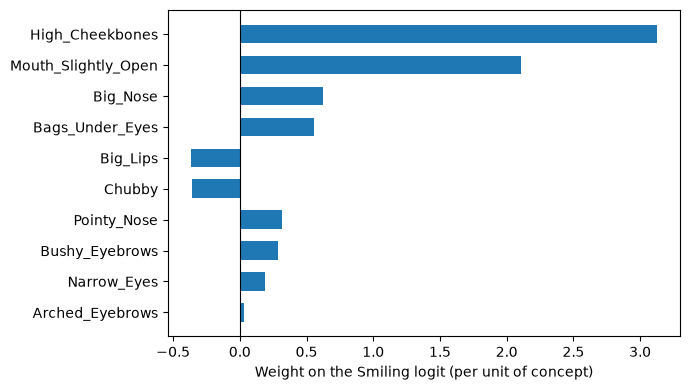

In [22]:
# Interpretability: the label head IS the explanation of a CBM's decision.
weights_report = pd.DataFrame({
    "Concept": CONCEPT_NAMES,
    "Weight": independent_head.weight.squeeze(0).numpy(),
    "Concept test AUROC": cbm_concept_test_metrics["auroc"],
})
weights_report["Odds ratio"] = np.exp(weights_report["Weight"])
weights_report = weights_report.sort_values("Weight", key=np.abs, ascending=False)
display(weights_report.round(3))
print(f"Intercept: {independent_head.bias.item():+.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
positions = np.arange(num_concepts)
ax.barh(positions, weights_report["Weight"], height=0.6)
ax.set_yticks(positions)
ax.set_yticklabels(weights_report["Concept"])
ax.invert_yaxis()
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Weight on the Smiling logit (per unit of concept)")
plt.tight_layout()
plt.show()

### Steerability: test-time interventions (Koh et al., §6; Havasi et al., Fig. 2)

A human who knows the true value of some concepts can overwrite the model's predictions for them. For every test image we replace the predicted values of *k* concepts with their ground-truth 0/1 labels and recompute the Smiling prediction, for *k* = 0 … 10. Concepts are chosen in random order, and each curve averages 100 random orders (the same orders for every model, so Part 4 can reuse them). At *k* = 10 every concept comes from the human, so f̂ sees exactly the kind of input it was trained on.

What to expect (Koh et al., Fig. 4): because f̂ was trained on true concepts, accuracy should rise steadily as more concepts are corrected.

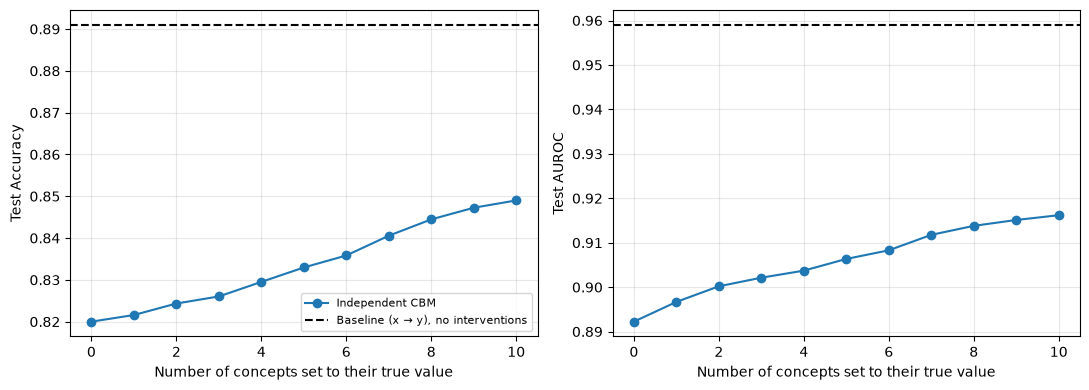

,"Accuracy, k=0","Accuracy, k=2","Accuracy, k=5","Accuracy, k=10",Gain k=0 → all (pp)
Independent CBM,0.82,0.8243,0.833,0.849,2.9


In [23]:
NUM_INTERVENTION_ORDERS = 100


@torch.no_grad()
def intervention_curve(score_fn, predicted_concepts, true_concepts, targets,
                       n_orders=NUM_INTERVENTION_ORDERS, seed=0):
    """Mean test accuracy/AUROC when k random concepts are set to their true values.

    score_fn maps an (n, K) concept matrix to (n,) logits.
    """
    rng = np.random.default_rng(seed)  # same seed → same concept orders for every model
    k_max = predicted_concepts.shape[1]
    accuracy = np.zeros((n_orders, k_max + 1))
    auroc = np.zeros((n_orders, k_max + 1))
    for r in range(n_orders):
        order = torch.as_tensor(rng.permutation(k_max), dtype=torch.long)
        for k in range(k_max + 1):
            concepts = predicted_concepts.clone()
            if k > 0:
                chosen = order[:k]
                concepts[:, chosen] = true_concepts[:, chosen]
            scores = binary_scores(targets, score_fn(concepts))
            accuracy[r, k], auroc[r, k] = scores["accuracy"], scores["auroc"]
    return pd.DataFrame({
        "Concepts intervened": np.arange(k_max + 1),
        "Accuracy": accuracy.mean(axis=0),
        "AUROC": auroc.mean(axis=0),
    })


def plot_interventions(results, baseline_scores):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for axis, metric in zip(axes, ["Accuracy", "AUROC"]):
        for name, curve in results.items():
            axis.plot(curve["Concepts intervened"], curve[metric], marker="o", label=name)
        axis.axhline(baseline_scores[metric.lower()], color="black", linestyle="--",
                     label="Baseline (x → y), no interventions")
        axis.set_xlabel("Number of concepts set to their true value")
        axis.set_ylabel(f"Test {metric}")
        axis.grid(alpha=0.3)
    axes[0].legend(fontsize=8)
    plt.tight_layout()
    plt.show()


def intervention_table(results):
    ks = sorted({0, min(2, num_concepts), min(5, num_concepts), num_concepts})
    table = pd.DataFrame({
        name: curve.set_index("Concepts intervened")["Accuracy"].loc[ks]
        for name, curve in results.items()
    }).T
    table.columns = [f"Accuracy, k={k}" for k in ks]
    table["Gain k=0 → all (pp)"] = 100 * (table.iloc[:, -1] - table.iloc[:, 0])
    return table


test_frozen = frozen["test"]
intervention_results = {
    "Independent CBM": intervention_curve(
        lambda c: head_logits(independent_head, c),
        test_frozen["soft_concepts"], test_frozen["true_concepts"], test_y),
}

plot_interventions(intervention_results, baseline_test_metrics)
display(intervention_table(intervention_results).round(4))

#### Part 3 — how to read these results
The gap between the CBM and the baseline splits into two parts, both read off the intervention table:
1. **All concepts intervened (k = 10) vs baseline:** can *any* CBM on these 10 concepts match the baseline? If even f̂ on the true concepts falls short, that part of the gap is structural: Smiling is not fully determined by these concepts, and the completeness estimate says by how much. Neither reference paper claims CBMs beat end-to-end models: Koh et al. report the independent bottleneck *worse* than the standard model on CUB (24.0% vs 17.5% error) and competitive on OAI, where the concepts are the clinical criteria that define the label.
2. **No interventions (k = 0) vs all concepts intervened:** the cost of predicting the concepts from 64×64 images. This part shrinks as the concept predictor improves, and it is also how much a human can recover by correcting the concepts (steerability).

**Interpretability:** the weight table is the model's explanation. Check that it is plausible (for Smiling you would expect `High_Cheekbones` and `Mouth_Slightly_Open` to dominate with positive weights) and note any weights that look like proxies rather than causes.

---
# Part 4 

## Hybrid CBM with side channel
Extend the CBM by adding a direct image-to-label pathway:

y = f(c) + s(x)

where:

- f(c) is the concept-based classifier, and

- s(x) is a side-channel head operating on backbone features.

The final prediction is obtained by summing the logits from both paths.

### Design of the hybrid: logit = f(ĉ) + s(x)

- **f(ĉ):** the Part 3 independent concept path, unchanged and frozen (same calibrated concepts, same head). Keeping it fixed means the concepts, their weights and the meaning of an intervention are identical to Part 3.
- **s(x):** a linear side head on the same frozen 512-d backbone features (standardised), fitted exactly with L-BFGS on cached features rather than with 20 noisy Adam epochs.
- **Side-channel penalty λ:** the objective is BCE + λ · mean(s(x)²). With λ = 0 the side channel takes whatever helps; as λ grows, s(x) → 0 and the pure CBM is recovered. Koh et al. (§8) flag the risk this controls: an unconstrained x → y path can reason about the concepts itself, so editing the concepts no longer controls the output. They suggest regularising that connection.

For each λ we record predictive performance, **how much of the decision comes from the concepts** (side-channel share of |logit|, and how often the concept path alone reaches the same decision), and **steerability** (accuracy when all 10 concepts are set to their true values).

In [35]:
if "cbm_test_metrics" not in globals() or "independent_head" not in globals():
    raise RuntimeError("Run Part 3 before Part 4.")


class FeatureStandardizer(nn.Module):
    def __init__(self, mean, std):
        super().__init__()
        self.register_buffer("mean", mean.detach().clone().float())
        self.register_buffer("std", std.detach().clone().float())

    def forward(self, features):
        return (features - self.mean) / self.std


class HybridCBM(nn.Module):
    """logit = f(c_hat) + s(x): the frozen concept path plus a side-channel head."""

    def __init__(self, concept_predictor, concept_label_head, concept_logit_offset, side_head):
        super().__init__()
        self.concept_predictor = concept_predictor
        self.concept_label_head = concept_label_head
        self.register_buffer("concept_logit_offset", concept_logit_offset.detach().clone().float())
        self.side_head = side_head

        self.concept_predictor.requires_grad_(False)
        self.concept_label_head.requires_grad_(False)
        self.concept_predictor.eval()
        self.concept_label_head.eval()

    def train(self, mode=True):
        super().train(mode)
        # Keep the inherited path fixed, including BatchNorm statistics.
        self.concept_predictor.eval()
        self.concept_label_head.eval()
        return self

    @torch.no_grad()
    def frozen_outputs(self, images):
        # ONE shared backbone evaluation supplies both paths.
        features = self.concept_predictor.backbone(images)
        concept_logits = self.concept_predictor.head(features) - self.concept_logit_offset
        concept_probabilities = torch.sigmoid(concept_logits)
        concept_path_logits = self.concept_label_head(concept_probabilities).squeeze(-1)
        return features, concept_probabilities, concept_path_logits

    def forward_from_features(self, features, concept_path_logits):
        return concept_path_logits + self.side_head(features).squeeze(-1)

    def forward(self, images):
        features, _, concept_path_logits = self.frozen_outputs(images)
        return self.forward_from_features(features, concept_path_logits)


# Standardise backbone features with TRAINING statistics (better-conditioned fit,
# comparable penalties across features).
feature_mean = frozen["train"]["features"].mean(dim=0)
feature_std = frozen["train"]["features"].std(dim=0).clamp_min(1e-6)
feature_standardizer = FeatureStandardizer(feature_mean, feature_std)

with torch.no_grad():
    standardized = {split: feature_standardizer(frozen[split]["features"]) for split in frozen}
concept_path = {split: head_logits(independent_head, frozen[split]["soft_concepts"]) for split in frozen}
print("Side-channel inputs (train):", tuple(standardized["train"].shape))

Side-channel inputs (train): (5000, 512)


,Weight decay,Validation AUROC,Validation accuracy
0,0.0001,0.8920,0.817
1,0.0010,0.8949,0.817
2,0.0100,0.9018,0.816


Selected side-head weight decay: 0.01


,λ (side penalty),Validation AUROC,Test accuracy,Test AUROC,Side share of |logit|,Decisions explained by concepts,"Accuracy, all concepts intervened",Intervention gain (pp)
0,0.00,0.9018,0.825,0.9018,0.4329,0.943,0.860,3.5
1,0.01,0.9020,0.825,0.9019,0.3275,0.947,0.858,3.3
2,0.03,0.9022,0.826,0.9025,0.2491,0.958,0.859,3.3
3,0.10,0.9010,0.823,0.9010,0.1530,0.973,0.856,3.3
4,0.30,0.8980,0.818,0.8975,0.0778,0.984,0.853,3.5
5,1.00,0.8948,0.815,0.8946,0.0293,0.993,0.855,4.0
6,3.00,0.8934,0.817,0.8932,0.0106,0.995,0.854,3.7
7,inf,0.8926,0.820,0.8922,0.0000,1.000,0.849,2.9


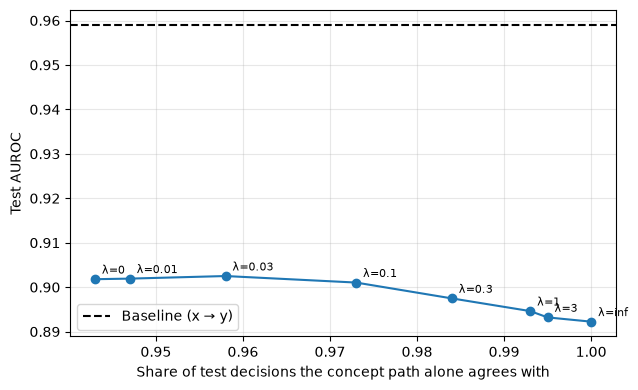

In [60]:
SIDE_WEIGHT_DECAYS = [1e-4, 1e-3, 1e-2]                  # regularisation of the 512-d side head
SIDE_PENALTIES = [0.0, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0]   # λ: how much the side channel may contribute


def fit_side_head(weight_decay, output_penalty):
    return fit_logistic_head(
        standardized["train"], frozen["train"]["target"], offset=concept_path["train"],
        weight_decay=weight_decay, output_penalty=output_penalty,
    )


def side_logits(head, split):
    return head_logits(head, standardized[split])


# Step 1: side-head regularisation, chosen on validation AUROC with λ = 0.
decay_rows = []
for weight_decay in SIDE_WEIGHT_DECAYS:
    head = fit_side_head(weight_decay, 0.0)
    scores = binary_scores(frozen["valid"]["target"], concept_path["valid"] + side_logits(head, "valid"))
    decay_rows.append({"Weight decay": weight_decay,
                       "Validation AUROC": scores["auroc"],
                       "Validation accuracy": scores["accuracy"]})
decay_report = pd.DataFrame(decay_rows)
display(decay_report.round(4))
SIDE_WEIGHT_DECAY = float(decay_report.loc[decay_report["Validation AUROC"].idxmax(), "Weight decay"])
print("Selected side-head weight decay:", SIDE_WEIGHT_DECAY)

# Step 2: sweep the side-channel penalty λ.
all_true_concept_path_test = head_logits(independent_head, frozen["test"]["true_concepts"])


def tradeoff_row(penalty, side_valid, side_test):
    f_test = concept_path["test"]
    test_scores = binary_scores(test_y, f_test + side_test)
    intervened = binary_scores(test_y, all_true_concept_path_test + side_test)
    side_size, concept_size = side_test.abs().mean().item(), f_test.abs().mean().item()
    return {
        "λ (side penalty)": penalty,
        "Validation AUROC": binary_scores(frozen["valid"]["target"], concept_path["valid"] + side_valid)["auroc"],
        "Test accuracy": test_scores["accuracy"],
        "Test AUROC": test_scores["auroc"],
        "Side share of |logit|": side_size / (side_size + concept_size),
        "Decisions explained by concepts": ((f_test >= 0) == (f_test + side_test >= 0)).float().mean().item(),
        "Accuracy, all concepts intervened": intervened["accuracy"],
        "Intervention gain (pp)": 100 * (intervened["accuracy"] - test_scores["accuracy"]),
    }


side_heads = {}
tradeoff_rows = []
for penalty in SIDE_PENALTIES:
    side_heads[penalty] = fit_side_head(SIDE_WEIGHT_DECAY, penalty)
    tradeoff_rows.append(tradeoff_row(penalty, side_logits(side_heads[penalty], "valid"),
                                      side_logits(side_heads[penalty], "test")))
# λ = ∞: no side channel, i.e. the pure independent CBM.
tradeoff_rows.append(tradeoff_row(float("inf"), torch.zeros(len(frozen["valid"]["target"])),
                                  torch.zeros(len(test_y))))
tradeoff_report = pd.DataFrame(tradeoff_rows)
display(tradeoff_report.round(4))

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(tradeoff_report["Decisions explained by concepts"], tradeoff_report["Test AUROC"], marker="o")
for _, row in tradeoff_report.iterrows():
    ax.annotate(f"λ={row['λ (side penalty)']:g}",
                (row["Decisions explained by concepts"], row["Test AUROC"]),
                textcoords="offset points", xytext=(5, 4), fontsize=8)
ax.axhline(baseline_test_metrics["auroc"], color="black", linestyle="--", label="Baseline (x → y)")
ax.set_xlabel("Share of test decisions the concept path alone agrees with")
ax.set_ylabel("Test AUROC")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

Each point on this graph is a different version of the hybrid model. The graph shows what you lose in interpretability as you let the side channel do more of the work.

Each point is the hybrid trained with a different side-channel penalty λ. A large λ forces the side channel s(x) towards zero; λ = 0 lets it contribute freely.
- λ = ∞ means no side channel at all. That point is your plain independent CBM.
- λ = 0 is an unconstrained side channel.
- The x-axis is an interpretability measure. For each test image, the hybrid decides “smiling / not smiling” from f(ĉ) + s(x). The x-axis is the fraction of images where the concept path f(ĉ) alone would make the same decision. At 1.00, the concepts explain every decision. At 0.94, the side channel overturns the concepts on 6% of images (about 57 of 1,000).

In [64]:
# Default: the λ with the best VALIDATION AUROC (λ = ∞, the pure CBM, is excluded).
# To favour interpretability, set HYBRID_PENALTY by hand to a larger λ whose validation
# AUROC is within your tolerance of the best, and justify that choice in the report.
HYBRID_PENALTY = None

finite_rows = tradeoff_report[np.isfinite(tradeoff_report["λ (side penalty)"])]
if HYBRID_PENALTY is None:
    HYBRID_PENALTY = float(finite_rows.loc[finite_rows["Validation AUROC"].idxmax(), "λ (side penalty)"])
if HYBRID_PENALTY not in side_heads:
    side_heads[HYBRID_PENALTY] = fit_side_head(SIDE_WEIGHT_DECAY, HYBRID_PENALTY)
print("Hybrid side-channel penalty λ:", HYBRID_PENALTY)

hybrid = HybridCBM(
    concept_predictor=copy.deepcopy(concept_model),
    concept_label_head=copy.deepcopy(independent_head),
    concept_logit_offset=concept_logit_offset,
    side_head=nn.Sequential(copy.deepcopy(feature_standardizer), copy.deepcopy(side_heads[HYBRID_PENALTY])),
).to(device)
hybrid.eval()

hybrid_side_test = side_logits(side_heads[HYBRID_PENALTY], "test")
hybrid_test_logits = concept_path["test"] + hybrid_side_test

# Sanity check: the full image → prediction module reproduces the cached computation.
_, hybrid_module_logits = predict_logits(hybrid, test_loader)
max_gap = (hybrid_module_logits - hybrid_test_logits).abs().max().item()
assert max_gap < 1e-3, f"Module and cached path disagree (max |Δ logit| = {max_gap:.2e})"
print(f"Sanity check passed: full hybrid and cached computation agree (max |Δ logit| = {max_gap:.1e}).")

hybrid_test_metrics = binary_scores(test_y, hybrid_test_logits)
hybrid_concept_test_metrics = cbm_concept_test_metrics  # the concept path is unchanged
hybrid_side_share = (hybrid_side_test.abs().mean()
                     / (hybrid_side_test.abs().mean() + concept_path["test"].abs().mean())).item()

hybrid_comparison_report = pd.DataFrame([
    score_row("Baseline (x → y)", test_y, baseline_test_logits),
    score_row("Independent CBM (x → c → y)", test_y, main_logits),
    score_row(f"Hybrid CBM (λ = {HYBRID_PENALTY:g})", test_y, hybrid_test_logits),
])
display(hybrid_comparison_report.round(4))

for reference_name, reference_logits in [("CBM", main_logits), ("baseline", baseline_test_logits)]:
    d = paired_difference_ci(test_y, hybrid_test_logits, reference_logits)
    print(f"Hybrid minus {reference_name}: accuracy {100 * d['accuracy_difference']:+.2f} pp "
          f"(95% CI {100 * d['accuracy_ci'][0]:+.2f} to {100 * d['accuracy_ci'][1]:+.2f}); "
          f"AUROC {d['auroc_difference']:+.4f} "
          f"(95% CI {d['auroc_ci'][0]:+.4f} to {d['auroc_ci'][1]:+.4f})")

print("----------------------------------")
print(f"Hybrid concept macro-accuracy: {hybrid_concept_test_metrics['macro_accuracy']:.4f}")
print(f"Hybrid concept macro-F1: {hybrid_concept_test_metrics['macro_f1']:.4f}")
print(f"Side-channel share of |logit| on test images: {hybrid_side_share:.2f}")
print("----------------------------------")

# Inspect the two paths for five test examples (as in the original notebook).
hybrid_path_examples = pd.DataFrame({
    "True Smiling": test_y[:5].int().numpy(),
    "Concept logit": concept_path["test"][:5].numpy(),
    "Side logit": hybrid_side_test[:5].numpy(),
    "Final logit": hybrid_test_logits[:5].numpy(),
    "P(Smiling)": torch.sigmoid(hybrid_test_logits[:5]).numpy(),
})
display(hybrid_path_examples.round(4))

Hybrid side-channel penalty λ: 0.03
Sanity check passed: full hybrid and cached computation agree (max |Δ logit| = 1.2e-06).


,Model,Test accuracy,Accuracy 95% CI,Test AUROC,AUROC 95% CI
0,Baseline (x → y),0.891,"[0.872, 0.909]",0.9590,"[0.948, 0.969]"
1,Independent CBM (x → c → y),0.820,"[0.797, 0.842]",0.8922,"[0.873, 0.910]"
2,Hybrid CBM (λ = 0.03),0.826,"[0.801, 0.848]",0.9025,"[0.883, 0.920]"


Hybrid minus CBM: accuracy +0.60 pp (95% CI -0.60 to +1.80); AUROC +0.0103 (95% CI +0.0037 to +0.0171)
Hybrid minus baseline: accuracy -6.50 pp (95% CI -9.00 to -4.10); AUROC -0.0565 (95% CI -0.0738 to -0.0406)
----------------------------------
Hybrid concept macro-accuracy: 0.8003
Hybrid concept macro-F1: 0.4634
Side-channel share of |logit| on test images: 0.25
----------------------------------


,True Smiling,Concept logit,Side logit,Final logit,P(Smiling)
0,0,-1.7943,-0.1362,-1.9305,0.1267
1,1,3.0062,1.3317,4.3380,0.9871
2,0,-1.2073,-1.3687,-2.5760,0.0707
3,0,-1.7358,-0.6644,-2.4001,0.0832
4,1,2.2716,1.2169,3.4885,0.9704


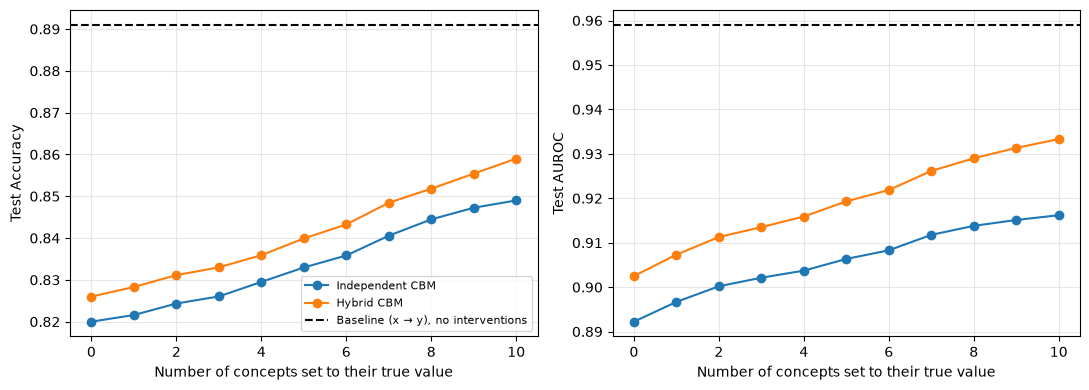

,"Accuracy, k=0","Accuracy, k=2","Accuracy, k=5","Accuracy, k=10",Gain k=0 → all (pp)
Independent CBM,0.820,0.8243,0.8330,0.849,2.9
Hybrid CBM,0.826,0.8311,0.8399,0.859,3.3


In [57]:
# Steerability of the hybrid: the same interventions change only f(c); s(x) stays as it is.
intervention_results["Hybrid CBM"] = intervention_curve(
    lambda c: head_logits(independent_head, c) + hybrid_side_test,
    test_frozen["soft_concepts"], test_frozen["true_concepts"], test_y,
)
compared = ["Independent CBM", "Hybrid CBM"]
plot_interventions({name: intervention_results[name] for name in compared}, baseline_test_metrics)
display(intervention_table({name: intervention_results[name] for name in compared}).round(4))

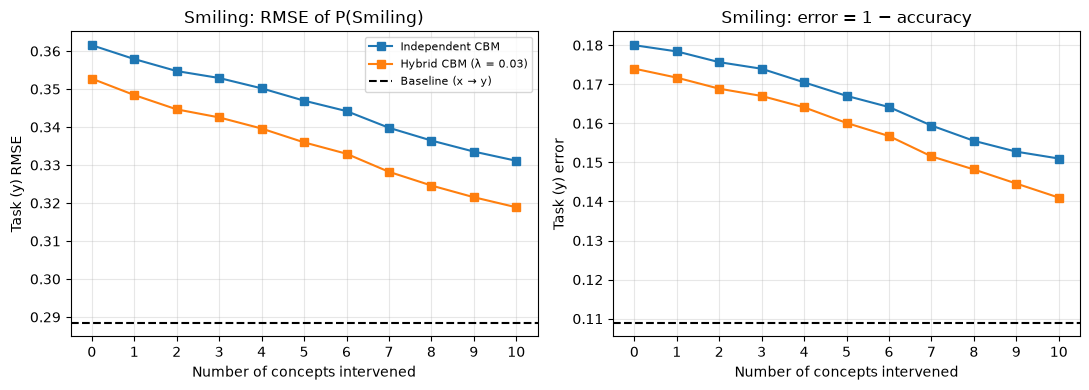

,"RMSE, k=0","RMSE, k=2","RMSE, k=5","RMSE, k=10"
Independent CBM,0.3615,0.3547,0.3469,0.3311
Hybrid CBM (λ = 0.03),0.3527,0.3447,0.3360,0.3189


Baseline RMSE: 0.2885 | baseline error: 0.1090


In [58]:
# Koh et al. (2020), Fig. 4: task error as more concepts are set to their true value.
# Their OAI task is a regression (a grade from 0 to 3), so they plot RMSE. For a binary target
# the matching quantity is the RMSE between P(Smiling) and the 0/1 label, i.e. the square root
# of the Brier score (0 = perfect, 0.5 = always answering 0.5). Their classification task (CUB)
# plots task error = 1 − accuracy instead, shown in the right panel.


@torch.no_grad()
def intervention_error_curve(score_fn, predicted_concepts, true_concepts, targets,
                             n_orders=NUM_INTERVENTION_ORDERS, seed=0):
    """Mean task RMSE and task error when k random concepts are set to their true values.

    Uses the same seed as intervention_curve, so the concept orders are identical.
    """
    rng = np.random.default_rng(seed)
    y = targets.float()
    k_max = predicted_concepts.shape[1]
    rmse = np.zeros((n_orders, k_max + 1))
    error = np.zeros((n_orders, k_max + 1))
    for r in range(n_orders):
        order = torch.as_tensor(rng.permutation(k_max), dtype=torch.long)
        for k in range(k_max + 1):
            concepts = predicted_concepts.clone()
            if k > 0:
                chosen = order[:k]
                concepts[:, chosen] = true_concepts[:, chosen]
            logits = score_fn(concepts)
            rmse[r, k] = torch.sqrt((torch.sigmoid(logits) - y).pow(2).mean()).item()
            error[r, k] = ((logits >= 0).float() != y).float().mean().item()
    return pd.DataFrame({
        "Concepts intervened": np.arange(k_max + 1),
        "Task RMSE": rmse.mean(axis=0),
        "Task error": error.mean(axis=0),
    })


error_curves = {
    "Independent CBM": intervention_error_curve(
        lambda c: head_logits(independent_head, c),
        test_frozen["soft_concepts"], test_frozen["true_concepts"], test_y),
    f"Hybrid CBM (λ = {HYBRID_PENALTY:g})": intervention_error_curve(
        lambda c: head_logits(independent_head, c) + hybrid_side_test,
        test_frozen["soft_concepts"], test_frozen["true_concepts"], test_y),
}

# The baseline has no concepts, so it is a flat reference line. Note: it memorised the training
# set, so its probabilities are over-confident (near 0 or 1 even when wrong), which inflates its
# RMSE relative to its error rate. Compare models on the error panel for accuracy, and read the
# RMSE panel as "accuracy + how honest the probabilities are".
baseline_rmse = torch.sqrt((torch.sigmoid(baseline_test_logits) - test_y).pow(2).mean()).item()
baseline_error = 1 - baseline_test_metrics["accuracy"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for axis, metric in zip(axes, ["Task RMSE", "Task error"]):
    for name, curve in error_curves.items():
        axis.plot(curve["Concepts intervened"], curve[metric], marker="s", label=name)
    axis.set_xlabel("Number of concepts intervened")
    axis.set_xticks(range(num_concepts + 1))
    axis.grid(alpha=0.3)
axes[0].axhline(baseline_rmse, color="black", linestyle="--", label="Baseline (x → y)")
axes[1].axhline(baseline_error, color="black", linestyle="--", label="Baseline (x → y)")
axes[0].set_ylabel("Task (y) RMSE")
axes[1].set_ylabel("Task (y) error")
axes[0].set_title("Smiling: RMSE of P(Smiling)")
axes[1].set_title("Smiling: error = 1 − accuracy")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

ks = sorted({0, min(2, num_concepts), min(5, num_concepts), num_concepts})
rmse_table = pd.DataFrame({
    name: curve.set_index("Concepts intervened")["Task RMSE"].loc[ks]
    for name, curve in error_curves.items()
}).T
rmse_table.columns = [f"RMSE, k={k}" for k in ks]
display(rmse_table.round(4))
print(f"Baseline RMSE: {baseline_rmse:.4f} | baseline error: {baseline_error:.4f}")

#### Part 4 — how to read these results
- The side head can only add information that is *linearly readable* from the frozen concept-backbone features; unlike the baseline, it cannot fine-tune the backbone for Smiling. Expect the hybrid to land between the CBM and the baseline.
- Read the trade-off table from λ = ∞ (pure CBM) up to λ = 0: accuracy rises while the side channel's share of the logit rises and the share of decisions the concepts alone explain falls. That is the interpretability cost of the side channel.
- **Steerability:** with all concepts set to their true values, the pure CBM reaches its k = 10 accuracy. In the hybrid, s(x) still contributes, so the same intervention moves the output less, and it can even hurt when s(x) was compensating for concept errors that the intervention removed. Compare the intervention-gain column across λ.
- Havasi et al. (2022) make the side channel latent, binary and stochastic, and train an amortisation network so it can be marginalised out when a fully concept-based explanation is needed. That is beyond this assignment, but it is the principled version of what λ approximates here.

In [59]:
def intervention_gain(name):
    curve = intervention_results[name]
    return 100 * (curve["Accuracy"].iloc[-1] - curve["Accuracy"].iloc[0])


summary_rows = []
for name, logits, curve_name, side_share in [
    ("Baseline (x → y)", baseline_test_logits, None, np.nan),
    ("Independent CBM (x → c → y)", main_logits, "Independent CBM", 0.0),
    (f"Hybrid CBM (λ = {HYBRID_PENALTY:g})", hybrid_test_logits, "Hybrid CBM", hybrid_side_share),
]:
    scores = binary_scores(test_y, logits)
    has_concepts = curve_name is not None
    summary_rows.append({
        "Model": name,
        "Test accuracy": scores["accuracy"],
        "Test AUROC": scores["auroc"],
        "Concept mean AUROC": cbm_concept_test_metrics["macro_auroc"] if has_concepts else np.nan,
        "Concept macro-F1": cbm_concept_test_metrics["macro_f1"] if has_concepts else np.nan,
        "Accuracy gain, all concepts given (pp)": intervention_gain(curve_name) if has_concepts else np.nan,
        "Side-channel share of |logit|": side_share,
    })
final_summary = pd.DataFrame(summary_rows)
display(final_summary.round(4))

,Model,Test accuracy,Test AUROC,Concept mean AUROC,Concept macro-F1,"Accuracy gain, all concepts given (pp)",Side-channel share of |logit|
0,Baseline (x → y),0.891,0.9590,NaN,NaN,NaN,NaN
1,Independent CBM (x → c → y),0.820,0.8922,0.7902,0.4634,2.9,0.0000
2,Hybrid CBM (λ = 0.03),0.826,0.9025,0.7902,0.4634,3.3,0.2491


---

---